# 37장 · 청크 크기·중첩·top-k 비교 실험

청크 크기는 조각의 길이, 중첩은 이웃 조각이 공유하는 길이, top-k는 가져올 결과 수입니다. 한 번에 하나만 바꿔야 각 설정의 영향을 읽을 수 있습니다.

검색 평가에서 기대한 원문을 찾았는데 답에 ‘14일’이 보이지 않습니다. 원문 한 쪽을 몇 글자씩 나누느냐에 따라 검색기에 보이는 조각이 달라집니다.

실행을 확인한 커널은 Python 3.12.15입니다.

Python 3 커널을 선택하고 위에서부터 실행하세요. 과제 셀에 직접 코드를 작성한 뒤 바로 아래에서 풀이를 펼쳐 보세요.


## chunk size와 원문 경계

여기서는 토큰 대신 파이썬 문자열의 글자 위치로 자릅니다. size는 한 조각의 최대 길이, overlap은 다음 조각 앞부분에 다시 들어갈 글자 수입니다. 먼저 크기만 바꾸어 첫 조각에 어떤 내용이 남았는지 읽습니다.

**청크 크기에 따른 원문 분할**　겹침을 0으로 고정했습니다. 크기 8이면 17글자가 8, 8, 1글자로 나뉩니다.

[웹 교재에서 열기](https://langchain-lecture.vercel.app/chapter37/index.html#practice-space)


### 실험의 통제 조건

<p>한 번에 size와 overlap을 모두 바꾸고 결과가 달라졌다면 어느 변경이 원인인지 구분하기 어렵습니다. 먼저 변경할 변수 하나를 정하고 나머지 설정과 입력을 유지합니다. 다음 변경은 바로 앞 설정을 기준으로 삼습니다.</p>

<p>청크 크기를 바꾸면 청크 본문과 벡터가 함께 달라집니다. 이는 바꾼 크기에 따라 다시 계산해야 하는 산출물입니다. 벡터 모델까지 바꾸는 것과는 다릅니다. 여기서는 동일 키워드 표현·차원·거리로 새 청크의 벡터를 다시 계산합니다.</p>

<table><caption>네 설정과 세 비교 쌍</caption><thead><tr><th scope="col">실험</th><th scope="col">size</th><th scope="col">overlap</th><th scope="col">k</th><th scope="col">비교 대상 / 변경 변수</th></tr>
</thead><tbody><tr><td>A</td><td>16</td><td>0</td><td>1</td><td>새 기준</td></tr>
<tr><td>B</td><td>8</td><td>0</td><td>1</td><td>A→B / size</td></tr>
<tr><td>C</td><td>8</td><td>4</td><td>1</td><td>B→C / overlap</td></tr>
<tr><td>D</td><td>8</td><td>4</td><td>2</td><td>C→D / k</td></tr>
</tbody></table>


### 셀 01 · split_text()의 청크 크기

도서 대출 원문을 둘로 나눕니다. 첫 조각 안에 어떤 숫자가 있나요?


In [1]:
def split_text(text, size, overlap):
    if not 0 <= overlap < size:
        raise ValueError("중첩은 0 이상이고 크기보다 작아야 합니다.")
    parts = []
    for start in range(0, len(text), size - overlap):
        parts.append(text[start:start + size])
        if start + size >= len(text):
            break
    return parts

text = '도서 대출 기간은 14일입니다.'
print(split_text(text, 16, 0))

['도서 대출 기간은 14일입니다', '.']


첫 조각에는 14일이, 다음 조각에는 마침표만 남았습니다. 원문이 짧아도 고정 글자 수로 자르면 의미 없는 조각이 생길 수 있습니다.


### 청크 크기와 문장 경계

<p>size는 Python 문자열에서 한 청크에 넣는 최대 문자 수입니다. 토큰 수가 아닙니다. size=16을 8로 줄이면 원문 하나가 더 많은 조각으로 나뉩니다. 숫자·조건·주어가 서로 떨어질 수 있으므로 청크 개수만 비교하지 말고 실제 문자열을 읽습니다.</p>

<p>대출 원문은 “도서 대출 기간은 14일입니다.”라는 규칙입니다. 제공 코드가 만든 8문자 첫 청크는 “도서 대출 기간”이고 숫자 14가 없습니다. 원문 ID는 맞게 찾더라도 답변에 필요한 부분이 검색 결과에서 빠질 수 있습니다.</p>

<table><caption>dev-01에서 실제 관찰한 첫 검색 청크</caption><thead><tr><th scope="col">설정</th><th scope="col">청크 ID</th><th scope="col">본문</th><th scope="col">원문 Recall</th></tr>
</thead><tbody><tr><td>A:16/0/k1</td><td>library-1:0</td><td>도서 대출 기간은 14일입니다</td><td>1.0</td></tr>
<tr><td>B:8/0/k1</td><td>library-1:0</td><td>도서 대출 기간</td><td>1.0</td></tr>
</tbody></table>


### 셀 02 · 청크 크기 단독 변경

중첩은 0으로 두고 같은 원문을 나눠 보세요.


In [2]:
parts = split_text(text, 8, 0)
print(parts)

['도서 대출 기간', '은 14일입니다', '.']


질문에 있는 ‘대출’과 답에 필요한 ‘14일’이 다른 조각으로 갈라졌습니다. 원문 ID 적중률만 같다고 답을 쓸 문맥까지 같은 것은 아닙니다.


### 청크 경계와 저장 벡터

<p>size를 16에서 8로 줄이면 같은 원문에서 잘라 낸 텍스트가 바뀝니다. 실제 벡터 인덱스를 만든다면 새 텍스트를 다시 임베딩해야 합니다. 이 셀에서는 그 전에 어느 글자가 어느 조각에 들어가는지 먼저 확인합니다.</p>


## overlap에 따른 공통 문자열

겹치는 글자가 있으면 경계에 걸친 문구를 함께 읽을 수 있습니다. 대신 같은 내용이 여러 검색 결과에 중복될 수 있습니다. 크기나 중첩을 바꾸면 그 조각들로 인덱스를 새로 만들어야 합니다.


### 과제 03 · 중첩 구간 슬라이싱

size=8, overlap=4로 나누어 첫 조각의 마지막 네 글자와 다음 조각의 첫 네 글자가 같은지 확인하세요.


In [3]:
# 같은 원문의 앞 두 조각을 비교하세요.

<details><summary>정답 코드와 실행 결과 보기</summary>
<pre><code>overlapped = split_text(text, 8, 4)
print(repr(overlapped[0][-4:]), repr(overlapped[1][:4]))</code></pre>
<p>실행 결과</p><pre><code>&#x27;출 기간&#x27; &#x27;출 기간&#x27;</code></pre>
<p>같은 네 글자가 양쪽에 보입니다. repr을 쓴 까닭은 공백도 한 글자에 들어가기 때문입니다. 다음 실험에서 k만 바꾼다면 이번에 만든 조각과 벡터를 그대로 사용하세요.</p>
</details>


### 인접 청크의 공통 텍스트

<p>중첩은 앞 청크의 끝부분을 다음 청크에도 넣는 것입니다. size=8/overlap=4이면 시작 위치는 4문자씩 이동합니다. 경계에 걸린 내용을 함께 남길 수 있지만 같은 문자가 여러 청크에 반복됩니다.</p>

<p>중첩을 늘려도 모든 질문의 필요한 정보가 한 청크에 모이는 것은 아닙니다. 이번 휴관 질문은 B의 첫 검색 본문이 “에 휴관합니다.”이고 C에서는 “ 월요일에 휴관”입니다. 요일이 검색 결과에 들어오는 변화가 있지만, 이것만으로 실제 의미 검색 성능이나 모든 문장의 완전성을 증명하지 않습니다.</p>

<table><caption>생성한 전체 청크 수</caption><thead><tr><th scope="col">설정</th><th scope="col">원문 수</th><th scope="col">청크 수</th><th scope="col">관찰</th></tr>
</thead><tbody><tr><td>A:16/0</td><td>3</td><td>5</td><td>기준 경계</td></tr>
<tr><td>B:8/0</td><td>3</td><td>8</td><td>짧게 나눔</td></tr>
<tr><td>C:8/4</td><td>3</td><td>12</td><td>반복 범위 추가</td></tr>
<tr><td>D:8/4</td><td>3</td><td>12</td><td>k만 바꿔 청크 그대로</td></tr>
</tbody></table>


## top-k와 검색 결과 수

이번에는 청크를 다시 만들지 않습니다. 37장 실험의 고정 인덱스(size=8, overlap=4)에서 대출 질문으로 찾은 상위 두 청크를 읽습니다. k는 정렬을 바꾸지 않고 앞에서 몇 개를 가져올지 정합니다.


### k가 2가 되면 찾은 원문도 두 개일까요?

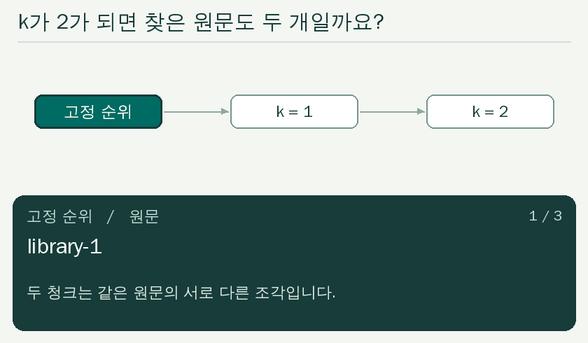

고정한 ranking을 앞에서부터 자릅니다. 둘째 청크의 ID는 달라도 원문 ID는 첫 청크와 같습니다.


### 셀 04 · top-k 변경과 검색 범위

아래 목록은 제공 실험에서 저장한 dev-01의 순위입니다. 어느 청크가 추가되는지 읽으세요.

추가로 찾은 조각 ‘출 기간은 14’에서 14 다음 글자를 확인하세요. 숫자는 보이지만 단위 ‘일’은 이 조각에 없습니다. 두 건을 찾았다는 사실만으로 답에 필요한 문장이 모두 들어왔다고 판단할 수 없습니다.


In [4]:
ranking = ['library-1:0', 'library-1:1']
print(ranking[:1])
print(ranking[:2])

['library-1:0']
['library-1:0', 'library-1:1']


두 번째 결과가 추가되지만 첫 번째 검색 결과는 그대로입니다. 청크 두 건이 같은 원문에서 왔다면 기대 원문을 두 개 찾은 것으로 세지 않습니다.


### 같은 순위에서 k만 바꾸기

<p>ranking[:1]은 첫 청크만, ranking[:2]는 둘째 청크까지 반환합니다. 두 ID가 모두 library-1에서 나왔으므로 청크 수는 늘어도 새 원문을 찾은 것은 아닙니다.</p>


### 원문 적중과 내용의 완전성

<p>library-1:0과 library-1:1은 같은 원문에서 나왔습니다. 원문을 맞혔다는 판정만으로는 선택한 청크에 ‘14일’이 들어 있는지 알 수 없습니다. 답변을 만들기 전에는 청크의 문자열도 읽어 보세요.</p>


## 돌아보기

크기와 k를 동시에 바꿀 경우 어느 쪽 때문에 답이 달라졌는지 나누기 어렵습니다. 다음 실험의 질문·원문·인덱스·k 가운데 고정할 항목을 먼저 적어 보세요.
